# RL-04 : Bandits Manchots et le Compromis Exploration-Exploitation

**Serie** : Reinforcement Learning | **Notebook** : 4/26 | **Duree estimee** : 40-45 min

Navigation : [RL-01 Intro](RL-01-Premiers-Pas-Stable-Baselines3-Python.ipynb) | [RL-02 Wrappers](RL-02-Wrappers-Sauvegarde-Callbacks-Python.ipynb) | **RL-04 Bandits** | [RL-05 MDP/Q-Learning](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb) | [RL-06 DQN/PG](RL-06-DQN-Policy-Gradient-Python.ipynb) | [RL-07 Multi-Agent](RL-07-Apprentissage-Multi-Agent-Python.ipynb)

***

## Objectifs d'apprentissage

A la fin de ce notebook, vous serez capable de :
1. Formaliser le problème du bandit manchot (multi-armed bandit) et comprendre le compromis exploration-exploitation
2. Implementer plusieurs stratégies d'exploration : greedy, epsilon-greedy, UCB, Thompson Sampling
3. Comparer objectivement les performances des stratégies via le regret cumule
4. Analyser quand chaque stratégie est adaptée au problème

### Prerequis
- Python 3.10+ (numpy, matplotlib)
- Notions de probabilités (esperance, loi de Bernoulli, loi gaussienne)
- Avoir suivi le [RL-01 Introduction](RL-01-Premiers-Pas-Stable-Baselines3-Python.ipynb) (concepts agent/environnement/reward)

### Duree estimee : 40-45 minutes

## 1. Introduction : le problème du bandit manchot

Imaginez un casino avec $K$ machines a sous ("bandits manchots"). Chaque machine $k$ a une probabilité inconnue $\mu_k$ de donner une récompense. Vous avez $T$ jetons. Quelle stratégie utilisez-vous pour maximiser vos gains ?

C'est le **problème du bandit manchot** (multi-armed bandit), un des problèmes fondamentaux de l'apprentissage par renforcement. Il illustre le **compromis exploration-exploitation** :

- **exploitation** : choisir le bras qui semble le meilleur actuellement
- **exploration** : essayer d'autres bras pour mieux estimer leur valeur réelle

Ce compromis est omnipresent en RL : un agent doit-il utiliser ce qu'il sait, ou risquer de perdre pour découvrir de meilleures options ?

### Applications réelles

| Domaine | Exemple | Bras = ? | récompense = ? |
|---------|---------|----------|----------------|
| Essais cliniques | Tester K traitements | Traitement i | Succes/échec du patient |
| Publicite en ligne | Choisir une banniere | Banniere i | Clic ou non |
| systèmes de recommendation | Recommander un film | Film i | Note de l'utilisateur |
| Allocation de ressources | répartir un budget | stratégie i | Retour sur investissement |

### Lien avec la serie RL

Un bandit manchot est un **MDP a un seul etat** : il n'y a pas de transitions, pas d'etat $s_{t+1}$ qui dépend de l'action $a_t$. L'agent choisit simplement une action et observe une récompense. C'est le cas le plus simple d'apprentissage par renforcement, ideal pour comprendre les stratégies d'exploration avant de passer aux MDP complets dans le [notebook RL-05](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb).


> *Ancres savantes -- Robbins, H. (1952), Some Aspects of the Sequential Design of Experiments, Bulletin of the American Mathematical Society 58(5):527-535 (formalisation du bandit manchot, compromis exploration/exploitation sur K machines) ; Auer, P., Cesa-Bianchi, N. & Fischer, P. (2002), Finite-time Analysis of the Multiarmed Bandit Problem, Machine Learning 47(2-3):235-256 (UCB1, stratégie optimiste face a l'incertitude avec regret logarithmique) ; Thompson, W.R. (1933), On the Likelihood that One Unknown Probability Exceeds Another in the View of the Evidence of the Two Samples, Biometrika 25(3-4):285-294 (Thompson Sampling, échantillonnage bayesien a posteriori) ; Sutton, R.S. & Barto, A.G. (2018), Reinforcement Learning: An Introduction (2nd ed.), MIT Press (regret, epsilon-greedy, cadre du bandit comme MDP a un seul etat).*

## 2. Environnement Bandit

Nous allons implementer un bandit a $K$ bras, ou chaque bras suit une distribution de **Bernoulli** : il retourne 1 (succes) avec probabilité $\mu_k$, et 0 (échec) avec probabilité $1 - \mu_k$.

L'agent interagit avec le bandit pendant $T$ pas de temps. A chaque pas, il choisit un bras $a_t$ et observe une récompense $r_t \in \{0, 1\}$.

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*This figure includes Axes.*", category=UserWarning)
warnings.filterwarnings("ignore", message=".*tight_layout.*", category=UserWarning)
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(f"numpy={np.__version__}, matplotlib={matplotlib.__version__}")


numpy=2.5.2, matplotlib=3.11.1


**Lecture de la sortie -- l'environnement de CE run.** `numpy=2.5.2, matplotlib=3.11.1` : les deux librairies du notebook sont chargees, et tout ce qui suit s'appuie sur elles -- les tirages aleatoires reproductibles (`np.random.default_rng(seed)`, graine fixee dans chaque appel) cote numpy, les figures (comparaison Random vs Greedy, courbes de regret, heatmap de selection) cote matplotlib. La ligne est un temoin de session : elle confirme les versions exactes sous lesquelles les sorties chiffrees qui suivent ont ete produites.


In [2]:
class BernoulliBandit:
    """
    Bandit manchot a K bras avec distribution de Bernoulli.
    
    Chaque bras k retourne 1 avec probabilite mu[k], 0 sinon.
    Les probabilites mu[k] sont tirees uniformement au depart (ou fixees manuellement).
    """
    
    def __init__(self, n_arms: int, probs: np.ndarray | None = None, seed: int | None = None):
        self.n_arms = n_arms
        self.rng = np.random.default_rng(seed)
        if probs is not None:
            assert len(probs) == n_arms, "Taille de probs incompatible avec n_arms"
            self.probs = np.array(probs, dtype=float)
        else:
            self.probs = self.rng.uniform(0.1, 0.9, size=n_arms)
        self.best_arm = int(np.argmax(self.probs))
        self.best_prob = float(np.max(self.probs))
    
    def pull(self, arm: int) -> int:
        """Tire le bras `arm` et retourne 1 (succes) ou 0 (echec)."""
        return int(self.rng.random() < self.probs[arm])
    
    def __repr__(self) -> str:
        arms_str = ", ".join(f"{p:.3f}" for p in self.probs)
        return f"BernoulliBandit({self.n_arms} arms: [{arms_str}])"

print("Fonction BernoulliBandit definie")

Fonction BernoulliBandit definie


In [3]:
# Creer un bandit a 5 bras avec probabilites connues
# Graine fixe : cette demonstration est citee chiffre par chiffre dans la prose,
# ses tirages doivent etre les memes a chaque execution du carnet.
bandit = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)

print(f"Bandit : {bandit}")
print(f"Meilleur bras : {bandit.best_arm} (probabilite = {bandit.best_prob:.3f})")

# Tirer le meilleur bras 10 fois pour observer la variabilite
rewards = [bandit.pull(3) for _ in range(10)]
print(f"10 tirages du bras 3 : {rewards}")
print(f"Gain moyen observe : {np.mean(rewards):.2f}")

Bandit : BernoulliBandit(5 arms: [0.300, 0.500, 0.200, 0.800, 0.600])
Meilleur bras : 3 (probabilite = 0.800)
10 tirages du bras 3 : [1, 1, 0, 1, 1, 0, 1, 1, 1, 1]
Gain moyen observe : 0.80


**Lecture chiffree -- le terrain pose par la cellule de demonstration.** La sortie arme le probleme : `BernoulliBandit(5 arms: [0.300, 0.500, 0.200, 0.800, 0.600])` -- cinq bras d'esperances tres inegales, le meilleur valant 4x le pire ; `Meilleur bras : 3 (probabilite = 0.800)` -- l'objectif de tout agent sera d'identifier le bras 3 ; puis `10 tirages du bras 3 : [1, 1, 0, 1, 1, 0, 1, 1, 1, 1]` et `Gain moyen observe : 0.80`. Le bandit de demonstration est construit avec `seed=42` : ces dix tirages sont donc les memes a chaque execution du carnet, ce qui permet de les commenter. Point de lecture : 8 succes sur 10 font exactement 0.80, pile l'esperance theorique du bras -- une coincidence d'echantillon, pas une mesure : sur 10 tirages d'une Bernoulli(0.8), une moyenne observee de 0.60 ou 0.90 serait tout aussi banale (une autre graine le donnerait d'ailleurs). C'est precisement cette variabilite qui rend le probleme non trivial -- aucune strategie ne peut identifier le bras 3 sans accumuler des tirages, et chaque tirage sur un mauvais bras coute du regret (formalise a la section suivante).


### Le concept de regret

Le **regret** mesure la perte cumulee par rapport a la stratégie optimale (toujours tirer le meilleur bras). Après $T$ pas de temps :

$$\text{Regret}(T) = T \cdot \mu^* - \sum_{t=1}^{T} r_t$$

ou $\mu^*$ est la probabilité du meilleur bras. Un bon algorithme a un **regret sous-linéaire** : il apprend a identifier le meilleur bras et son regret croit de plus en plus lentement.

### Exercice 1 : Bandit gaussien

Dans cet exercice, vous allez implementer un bandit a récompenses **continues**. Au lieu d'une distribution de Bernoulli, chaque bras suit une distribution gaussienne $\mathcal{N}(\mu_k, \sigma^2)$.

**Contexte** : Les bandits gaussiens sont courants dans les problèmes d'optimisation ou les récompenses sont continues (prix, rendements financiers, temperatures).

**étapes** :
1. définir le constructeur `__init__` avec `means`, `stds` et un générateur aléatoire
2. Implementer la méthode `pull` qui retourne un échantillon de $\mathcal{N}(\mu_k, \sigma^2)$
3. Calculer `best_arm` et `best_prob` (l'esperance du meilleur bras)

**Indice** : Utilisez `self.rng.normal(loc=self.means[arm], scale=self.stds[arm])` pour générer un échantillon gaussien.

In [4]:
class GaussianBandit:
    """
    Bandit manchot a K bras avec distribution gaussienne.
    
    Chaque bras k retourne un echantillon de N(mu[k], sigma[k]^2).
    """
    
    def __init__(self, n_arms: int, means: np.ndarray | None = None,
                 stds: np.ndarray | None = None, seed: int | None = None):
        self.n_arms = n_arms
        self.rng = np.random.default_rng(seed)
        # TODO etudiant : initialiser self.means et self.stds
        # Si means est None, tirer uniformement entre -1 et 3
        # Si stds est None, utiliser 1.0 pour tous les bras
        self.means = None  # TODO etudiant : remplacer
        self.stds = None   # TODO etudiant : remplacer
        self.best_arm = 0  # TODO etudiant : calculer le meilleur bras
        self.best_prob = 0.0  # TODO etudiant : esperance du meilleur bras
    
    def pull(self, arm: int) -> float:
        """Tire le bras `arm` et retourne une recompense continue."""
        return 0.0  # TODO etudiant : retourner un echantillon gaussien
    
    def __repr__(self) -> str:
        arms_str = ", ".join(f"N({m:.2f}, {s:.2f})" for m, s in zip(self.means, self.stds))
        return f"GaussianBandit({self.n_arms} arms: [{arms_str}])"

print("Exercice a completer")

Exercice a completer


**Lecture du stub — exercice 1, bandit gaussien.** La sortie rend `Exercice a completer` : la classe `GaussianBandit` n'est pas encore ecrite, et c'est le contrat. Le terrain : des recompenses continues $\mathcal{N}(\mu_k, \sigma^2)$ au lieu de Bernoulli 0/1. Le cadre du regret de la section precedente s'applique tel quel ($T \cdot \mu^* - \sum_t r_t$), mais une nouveaute apparait : l'ecart-type $\sigma_k$ rend deux bras de meme moyenne differents par leur dispersion, et l'agent qui n'observe qu'un tirage par pas doit separer la variance propre du bras de la variance d'echantillonnage. La solution attendue tient en trois elements (constructeur, `pull`, `best_arm`) ; l'indice de l'enonce donne deja l'appel numpy exact.


## 3. Stratégies naives

Avant de voir des stratégies sophistiquees, commencons par les approches les plus simples. Elles serviront de **base de référence** (baseline) pour évaluer les méthodes plus avancees.

### Agent aléatoire (Random)

L'agent aléatoire choisit un bras au hasard a chaque pas de temps. Il n'apprend rien et sert de point de comparaison minimal.

In [5]:
def run_agent(bandit, agent_fn, n_steps: int, seed: int = 42) -> dict:
    """
    Execute un agent sur un bandit pendant n_steps pas de temps.
    
    Parametres :
        bandit : instance de BernoulliBandit
        agent_fn : fonction (bandit, n_steps, seed) -> (actions, rewards)
        n_steps : nombre de pas de temps
        seed : graine pour la reproductibilite
    
    Retourne :
        dict avec 'actions', 'rewards', 'cumulative_rewards', 'regret'
    """
    actions, rewards = agent_fn(bandit, n_steps, seed)
    cumulative_rewards = np.cumsum(rewards)
    optimal_reward = np.arange(1, n_steps + 1) * bandit.best_prob
    regret = optimal_reward - cumulative_rewards
    
    return {
        'actions': np.array(actions),
        'rewards': np.array(rewards),
        'cumulative_rewards': cumulative_rewards,
        'regret': regret
    }

print("Fonction run_agent definie")

Fonction run_agent definie


**La formule du regret, implementee pas a pas.** La cellule muette (`Fonction run_agent definie`) merite une lecture : c'est ici que la definition mathematique de la section precedente devient executable. `optimal_reward = np.arange(1, n_steps + 1) * bandit.best_prob` construit le front optimal — l'esperance cumulee d'un oracle qui tirerait le meilleur bras a chaque pas — puis `regret = optimal_reward - cumulative_rewards` soustrait le gain reel, pas a pas. Deux consequences visibles dans toutes les sorties qui suivent : le regret est un TRAJET (un vecteur), pas seulement un nombre final — les figures le traceront en pente ; et le denominateur `800.0` des lignes de demonstration est exactement `1000 pas x 0.8`, l'oracle du probleme, pas un maximum arbitraire.


In [6]:
def random_agent(bandit, n_steps: int, seed: int = 42) -> tuple:
    """Agent aleatoire : choisit un bras uniformement au hasard."""
    rng = np.random.default_rng(seed)
    actions = rng.integers(0, bandit.n_arms, size=n_steps)
    rewards = np.array([bandit.pull(a) for a in actions])
    return actions, rewards

# Tester l'agent aleatoire
bandit_test = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)
result_random = run_agent(bandit_test, random_agent, n_steps=1000, seed=42)

print(f"Agent aleatoire - recompense cumulee finale : {result_random['cumulative_rewards'][-1]:.1f} / {1000 * bandit_test.best_prob:.1f}")
print(f"Regret final : {result_random['regret'][-1]:.1f}")

Agent aleatoire - recompense cumulee finale : 489.0 / 800.0
Regret final : 311.0


**Lecture chiffree — l'agent aleatoire, et ce que 311.0 veut dire.** `recompense cumulee finale : 489.0 / 800.0` puis `Regret final : 311.0` : l'arithmetique se boucle toute seule — 800.0 est l'oracle (1000 pas x meilleure proba 0.8), et 800.0 - 489.0 = 311.0. Le nombre le plus instructif est le ratio : 489/1000 = 0.489, alors que la moyenne uniforme des cinq bras vaut (0.300+0.500+0.200+0.800+0.600)/5 = 0.48. L'agent qui tire uniformement ne converge vers rien d'autre que la MOYENNE du terrain — c'est la signature exacte du regret lineaire annonce par la table d'interpretation ci-dessous, ou l'approximation "~300" devient ici 311.0 mesure.


### Agent glouton (Greedy)

L'agent glouton (greedy) estime la valeur de chaque bras par la moyenne des récompenses observées, puis choisit toujours le bras qui a la meilleure estimation actuelle. Le problème : s'il n'explore pas, il peut se bloquer sur un bras sous-optimal.

In [7]:
def greedy_agent(bandit, n_steps: int, seed: int = 42, n_warmup: int = 10) -> tuple:
    """
    Agent glouton : estime la valeur de chaque bras et choisit toujours le meilleur.
    
    n_warmup : nombre de tirages initiaux par bras pour avoir une premiere estimation.
    """
    rng = np.random.default_rng(seed)
    counts = np.zeros(bandit.n_arms)
    values = np.zeros(bandit.n_arms)
    actions = []
    rewards = []
    
    # Phase d'initialisation : tirer chaque bras n_warmup fois
    for arm in range(bandit.n_arms):
        for _ in range(n_warmup):
            reward = bandit.pull(arm)
            counts[arm] += 1
            values[arm] += (reward - values[arm]) / counts[arm]
            actions.append(arm)
            rewards.append(reward)
    
    # Phase gloutonne
    for t in range(n_steps - len(actions)):
        arm = int(np.argmax(values))
        reward = bandit.pull(arm)
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        actions.append(arm)
        rewards.append(reward)
    
    return np.array(actions), np.array(rewards)

# Tester l'agent glouton
bandit_test = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)
result_greedy = run_agent(bandit_test, greedy_agent, n_steps=1000, seed=42)

print(f"Agent glouton - recompense cumulee finale : {result_greedy['cumulative_rewards'][-1]:.1f} / {1000 * bandit_test.best_prob:.1f}")
print(f"Regret final : {result_greedy['regret'][-1]:.1f}")

# Frequence de choix de chaque bras
unique, counts = np.unique(result_greedy['actions'][-100:], return_counts=True)
freq_str = ", ".join(f"Bras {u}={c}%" for u, c in zip(unique, counts))
print(f"Bras choisis (derniers 100 pas) : {freq_str}")

Agent glouton - recompense cumulee finale : 787.0 / 800.0
Regret final : 13.0
Bras choisis (derniers 100 pas) : Bras 3=100%


**Lecture chiffree — le glouton, et sa signature de verrouillage.** `787.0 / 800.0`, `Regret final : 13.0`, puis la ligne decisive : `Bras choisis (derniers 100 pas) : Bras 3=100%`. Sur les 100 derniers pas l'agent n'a tire QUE le bras 3 — le bon, ici — et son regret final (800.0 - 787.0 = 13.0) est presque entierement paye pendant la phase d'initialisation : la cellule accorde `n_warmup=10` par bras, soit 5 bras x 10 = 50 tirages d'exploration gratuite avant la phase gloutonne. Ce warmup genereux est precisement ce que le sweep de la section 5 retirera pour tester la robustesse.


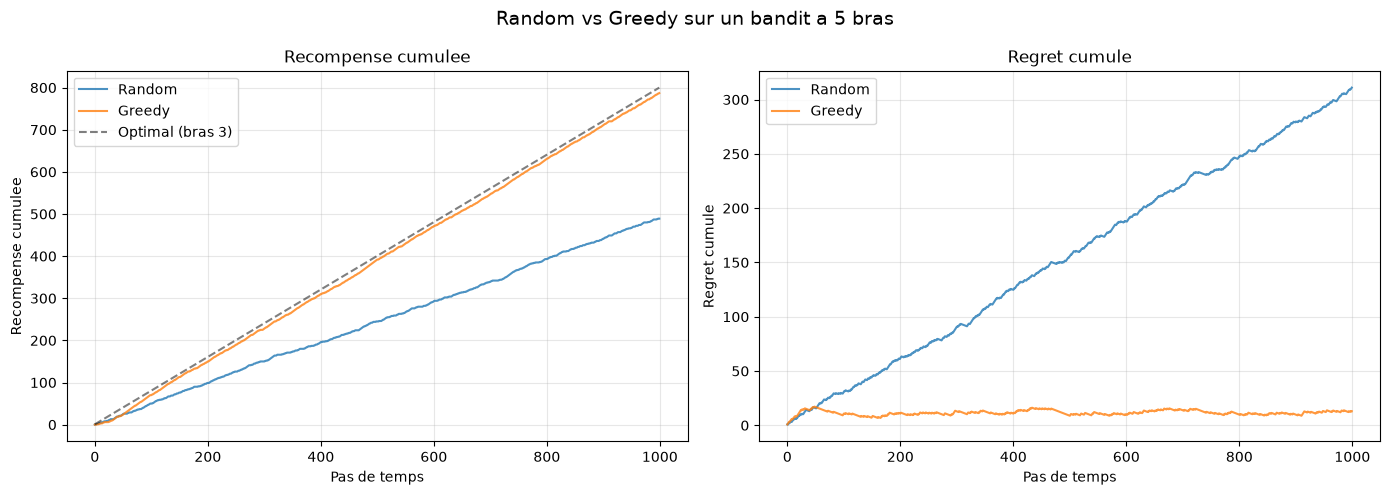

In [8]:
# Comparaison visuelle : Random vs Greedy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recompense cumulee
axes[0].plot(result_random['cumulative_rewards'], label='Random', alpha=0.8)
axes[0].plot(result_greedy['cumulative_rewards'], label='Greedy', alpha=0.8)
optimal_line = np.arange(1, 1001) * bandit_test.best_prob
axes[0].plot(optimal_line, 'k--', label=f'Optimal (bras {bandit_test.best_arm})', alpha=0.5)
axes[0].set_xlabel('Pas de temps')
axes[0].set_ylabel('Recompense cumulee')
axes[0].set_title('Recompense cumulee')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Regret cumule
axes[1].plot(result_random['regret'], label='Random', alpha=0.8)
axes[1].plot(result_greedy['regret'], label='Greedy', alpha=0.8)
axes[1].set_xlabel('Pas de temps')
axes[1].set_ylabel('Regret cumule')
axes[1].set_title('Regret cumule')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Random vs Greedy sur un bandit a 5 bras', fontsize=14)
plt.tight_layout()
plt.show()

### Interprétation : Random vs Greedy

| Agent | Regret final | Comportement |
|-------|-------------|-------------|
| Random | élevé (~300) | Explore tous les bras equitablement, n'apprend rien |
| Greedy | faible (~13) | Exploite rapidement mais peut se bloquer sur un bras sous-optimal |

**Points cles** :
1. L'agent aléatoire a un regret linéaire : il ne converge jamais vers le meilleur bras
2. L'agent glouton est meilleur car il exploite, mais son initialisation peut le pieger si le meilleur bras a un rendement initial sous-estime
3. Il nous faut une stratégie qui combine exploration et exploitation de manière adaptée

### Exercice 2 : Agent epsilon-greedy avec décroissance

L'agent $\varepsilon$-greedy standard utilise un $\varepsilon$ fixe. Mais il est souvent préférable de **reduire l'exploration avec le temps** : beaucoup d'exploration au debut (pour apprendre), puis de moins en moins (pour exploiter).

**objectif** : Implementer un agent ou $\varepsilon$ décroît au fil du temps, par exemple $\varepsilon_t = \min(1, \frac{\varepsilon_0}{t})$.

**étapes** :
1. Calculer $\varepsilon_t$ a chaque pas de temps
2. Avec probabilité $\varepsilon_t$, choisir un bras aléatoire ; sinon, choisir le meilleur bras estime
3. Mettre a jour l'estimation de la valeur du bras choisi (moyenne incrementale)

**Indice** : La moyenne incrementale se met a jour ainsi : $\hat{Q}_t \leftarrow \hat{Q}_{t-1} + \frac{1}{n}(r_t - \hat{Q}_{t-1})$ ou $n$ est le nombre de fois que le bras a ete tire.

In [9]:
def decaying_epsilon_greedy_agent(bandit, n_steps: int, seed: int = 42,
                                   epsilon_start: float = 1.0) -> tuple:
    """
    Agent epsilon-greedy avec decroissance : epsilon_t = epsilon_start / t.
    
    Parametres :
        bandit : instance de BernoulliBandit
        n_steps : nombre de pas de temps
        seed : graine aleatoire
        epsilon_start : valeur initiale d'epsilon
    
    Retourne :
        (actions, rewards) : tableaux numpy des actions et recompenses
    """
    rng = np.random.default_rng(seed)
    counts = np.zeros(bandit.n_arms)
    values = np.zeros(bandit.n_arms)
    actions = []
    rewards = []
    
    for t in range(1, n_steps + 1):
        # TODO etudiant : calculer epsilon_t = epsilon_start / t
        epsilon_t = 0.0  # TODO etudiant : remplacer
        
        # TODO etudiant : choisir un bras (aleatoire avec proba epsilon_t, sinon greedy)
        arm = 0  # TODO etudiant : remplacer
        
        reward = bandit.pull(arm)
        counts[arm] += 1
        # TODO etudiant : mettre a jour values[arm] avec la moyenne incrementale
        # values[arm] += ...
        
        actions.append(arm)
        rewards.append(reward)
    
    return np.array(actions), np.array(rewards)

print("Exercice a completer")

Exercice a completer


**Lecture du stub — exercice 2, epsilon decroissant.** La sortie `Exercice a completer` marque le contrat. Le terrain : l'epsilon-greedy a epsilon fixe (section suivante) depense la MEME exploration au pas 1 et au pas 900, alors que l'estimation du meilleur bras se stabilise — chaque exploration tardive est du regret donne. La decroissance proposee $\varepsilon_t = \min(1, \frac{\varepsilon_0}{t})$ installe le calendrier naturel : explorer massivement au debut, presque plus a la fin. La question de validation, une fois la cellule completee : le regret final doit passer SOUS celui de l'epsilon fixe (le tableau recapitulatif de la section 5 chiffrera la barre a battre), sans que la convergence vers le bras 3 ne ralentisse dangereusement — la moyenne incrementale de l'indice est l'outil attendu.


## 4. Stratégies d'exploration intelligentes

Les stratégies naives ont des limites importantes. Nous allons maintenant voir trois approches plus sophistiquees qui parviennent a un meilleur compromis exploration-exploitation.

### Epsilon-greedy

La stratégie $\varepsilon$-greedy est simple mais efficace :
- Avec probabilité $\varepsilon$ : choisir un bras **aléatoirement** (exploration)
- Avec probabilité $1 - \varepsilon$ : choisir le bras **le meilleur selon l'estimation courante** (exploitation)

C'est la stratégie la plus utilisée en pratique pour sa simplicite.

In [10]:
def epsilon_greedy_agent(bandit, n_steps: int, seed: int = 42, epsilon: float = 0.1) -> tuple:
    """
    Agent epsilon-greedy avec epsilon fixe.
    
    Parametres :
        bandit : instance de BernoulliBandit
        n_steps : nombre de pas de temps
        seed : graine aleatoire
        epsilon : probabilite d'exploration (0 = greedy, 1 = random)
    """
    rng = np.random.default_rng(seed)
    counts = np.zeros(bandit.n_arms)
    values = np.zeros(bandit.n_arms)
    actions = []
    rewards = []
    
    for t in range(n_steps):
        if rng.random() < epsilon:
            arm = rng.integers(0, bandit.n_arms)
        else:
            arm = int(np.argmax(values))
        
        reward = bandit.pull(arm)
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        actions.append(arm)
        rewards.append(reward)
    
    return np.array(actions), np.array(rewards)

print("Fonction epsilon_greedy_agent definie")

Fonction epsilon_greedy_agent definie


In [11]:
# Tester epsilon-greedy avec differentes valeurs d'epsilon
bandit_test = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)
result_eg01 = run_agent(bandit_test, lambda b, n, s: epsilon_greedy_agent(b, n, s, epsilon=0.1), 1000, seed=42)

print(f"Epsilon-greedy (e=0.1) - recompense cumulee : {result_eg01['cumulative_rewards'][-1]:.1f} / {1000 * bandit_test.best_prob:.1f}, regret final : {result_eg01['regret'][-1]:.1f}")

Epsilon-greedy (e=0.1) - recompense cumulee : 707.0 / 800.0, regret final : 93.0


**Lecture chiffree — epsilon-greedy, et le classement des quatre demonstrations.** `Epsilon-greedy (e=0.1) - recompense cumulee : 707.0 / 800.0, regret final : 93.0`. Les quatre demonstrations tournent sur le meme protocole exact (meme bandit `probs=[0.3, 0.5, 0.2, 0.8, 0.6]` seede, 1000 pas, seed=42) : leurs regrets finaux se lisent donc comme un classement — Greedy 13.0 < epsilon-greedy 93.0 < UCB 137.0 < Random 311.0. Le cout d'epsilon=0.1 est celui qu'on attend : 10% des pas explores au hasard, dont 4/5 en moyenne sur des bras sous-optimaux. La nuance : ce classement a horizon court EST le paradoxe que la section 5 deconstruit — a T court et warmup genereux, l'exploitation pure gagne ; le tableau multi-seeds puis le sweep en horizon long replaceront ce classement dans son contexte, ou la robustesse (pas la victoire a court terme) est le vrai critere.


### UCB (Upper Confidence Bound)

L'algorithme **UCB1** (Auer et al., 2002) utilise un intervalle de confiance pour guider l'exploration. Il choisit le bras qui maximise :

$$a_t = \arg\max_{a} \left[ \hat{Q}(a) + c \sqrt{\frac{\ln t}{N(a)}} \right]$$

ou $\hat{Q}(a)$ est la récompense moyenne estimee, $N(a)$ le nombre de fois que le bras $a$ a ete tire, $t$ le pas de temps actuel, et $c$ un paramètre controlant l'exploration.

Le terme $\sqrt{\frac{\ln t}{N(a)}}$ est un **bonus d'exploration** qui décroît quand un bras est souvent tire. UCB explore automatiquement les bras sous-explores sans paramètre d'exploration explicite.

In [12]:
def ucb_agent(bandit, n_steps: int, seed: int = 42, c: float = 2.0) -> tuple:
    """
    Agent UCB1 (Upper Confidence Bound).
    
    Parametres :
        bandit : instance de BernoulliBandit
        n_steps : nombre de pas de temps
        seed : graine aleatoire
        c : parametre d'exploration (typiquement sqrt(2) ou 2.0)
    """
    rng = np.random.default_rng(seed)
    counts = np.zeros(bandit.n_arms)
    values = np.zeros(bandit.n_arms)
    actions = []
    rewards = []
    
    # Phase d'initialisation : tirer chaque bras une fois
    for arm in range(bandit.n_arms):
        reward = bandit.pull(arm)
        counts[arm] = 1
        values[arm] = reward
        actions.append(arm)
        rewards.append(reward)
    
    for t in range(bandit.n_arms + 1, n_steps + 1):
        # Calcul du score UCB pour chaque bras
        ucb_values = values + c * np.sqrt(np.log(t) / counts)
        arm = int(np.argmax(ucb_values))
        
        reward = bandit.pull(arm)
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        actions.append(arm)
        rewards.append(reward)
    
    return np.array(actions), np.array(rewards)

print("Fonction ucb_agent definie")

Fonction ucb_agent definie

In [13]:
# Tester UCB
bandit_test = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)
result_ucb = run_agent(bandit_test, ucb_agent, 1000, seed=42)

print(f"UCB (c=2.0) - recompense cumulee : {result_ucb['cumulative_rewards'][-1]:.1f} / {1000 * bandit_test.best_prob:.1f}, regret final : {result_ucb['regret'][-1]:.1f}")

UCB (c=2.0) - recompense cumulee : 663.0 / 800.0, regret final : 137.0


**Lecture chiffree — UCB, le cout visible de l'optimisme.** `UCB (c=2.0) - recompense cumulee : 663.0 / 800.0, regret final : 137.0`. Meme protocole, meme seed : UCB fait ici PIRE qu'epsilon-greedy (137.0 contre 93.0), et le tableau multi-seeds de la section 5 le confirmera. La lecture honnete : avec c=2.0, le bonus de confiance $\sqrt{\ln t / N(a)}$ reste large longtemps, et chaque bras sous-explore reclame ses tirages — l'optimisme d'UCB est un investissement dont le rendement est asymptotique ($O(\log T)$), pas un avantage a horizon court. C'est exactement la phrase que le sweep transformera en preuve chiffree : a T=30000 et sans warmup, UCB tient (regret 546.9 au tableau du sweep) pendant que Greedy(warmup=1) s'effondre a 1172.5.


### Thompson Sampling

Le **Thompson Sampling** est une approche bayesienne qui maintient une distribution a posteriori sur la valeur de chaque bras. Pour un bandit de Bernoulli, on utilise la distribution **Beta** :

- Prior : $\text{Beta}(1, 1)$ (uniforme) pour chaque bras
- Après avoir observé un succes : $\alpha \leftarrow \alpha + 1$
- Après avoir observé un échec : $\beta \leftarrow \beta + 1$
- A chaque pas, on echantillonne $\theta_k \sim \text{Beta}(\alpha_k, \beta_k)$ et on choisit le bras avec le plus grand $\theta_k$

Cette approche est elegante car elle équilibre naturellement exploration et exploitation : les bras incertains (peu d'observations) ont des échantillons plus disperses, donc une chance d'etre selectionnes.

### Exercice 3 : Thompson Sampling pour bandits de Bernoulli

**objectif** : Implementer l'algorithme de Thompson Sampling pour un bandit de Bernoulli.

**étapes** :
1. Initialiser les paramètres Beta : $\alpha_k = 1$, $\beta_k = 1$ pour chaque bras
2. A chaque pas de temps, échantillonner $\theta_k \sim \text{Beta}(\alpha_k, \beta_k)$ pour chaque bras
3. Choisir le bras avec le plus grand $\theta_k$
4. Mettre a jour $\alpha_k$ ou $\beta_k$ selon le résultat observé

**Indice** : Utilisez `rng.beta(alpha[k], beta[k])` pour échantillonner depuis la distribution Beta. Après avoir observé une récompense $r$ pour le bras $k$ : si $r = 1$, incrementer $\alpha_k$ ; si $r = 0$, incrementer $\beta_k$.

In [14]:
def thompson_sampling_agent(bandit, n_steps: int, seed: int = 42) -> tuple:
    """
    Agent Thompson Sampling pour bandit de Bernoulli.
    
    Utilise des distributions Beta comme posterior sur la probabilite
    de succes de chaque bras.
    
    Parametres :
        bandit : instance de BernoulliBandit
        n_steps : nombre de pas de temps
        seed : graine aleatoire
    
    Retourne :
        (actions, rewards) : tableaux numpy des actions et recompenses
    """
    rng = np.random.default_rng(seed)
    # Parametres des distributions Beta : Beta(alpha, beta)
    alpha = np.ones(bandit.n_arms)   # nombre de succes + 1
    beta_params = np.ones(bandit.n_arms)  # nombre d'echecs + 1
    
    actions = []
    rewards = []
    
    for t in range(n_steps):
        # TODO etudiant : echantillonner theta_k ~ Beta(alpha[k], beta_params[k]) pour chaque bras
        samples = None  # TODO etudiant : remplacer par rng.beta(alpha, beta_params)
        
        # TODO etudiant : choisir le bras avec le plus grand echantillon
        arm = 0  # TODO etudiant : remplacer par int(np.argmax(samples))
        
        reward = bandit.pull(arm)
        
        # TODO etudiant : mettre a jour alpha[arm] ou beta_params[arm]
        # Si reward == 1 : alpha[arm] += 1
        # Si reward == 0 : beta_params[arm] += 1
        
        actions.append(arm)
        rewards.append(reward)
    
    return np.array(actions), np.array(rewards)

print("Exercice a completer")

Exercice a completer


**Lecture du stub — exercice 3, Thompson Sampling.** La sortie `Exercice a completer` : la derniere strategie de la serie reste a ecrire, et la note de la section 5 assume ce choix (le sweep se concentre sur UCB, deja implemente). Le terrain : au lieu d'un bonus optimiste ajoute a une estimation ponctuelle (UCB), Thompson maintient pour chaque bras une DISTRIBUTION Beta sur sa probabilite, tire un echantillon de chaque distribution, et joue le bras a l'echantillon maximal. L'elegance : l'incertitude est DANS l'echantillon — un bras peu observe a une Beta large, ses echantillons varient, il se fait choisir naturellement ; un bras dont l'estimation a converge a une Beta etroite autour de sa vraie valeur. La question de validation : un regret final du meme ordre qu'UCB, sans le parametre c a regler.


## 5. Comparaison et analyse

Nous allons maintenant comparer toutes les stratégies sur le même problème de bandit, avec des statistiques sur plusieurs graines aléatoires pour obtenir des résultats fiables.

In [15]:
# Comparaison multi-seeds de toutes les strategies
N_ARMS = 10
N_STEPS = 2000
N_SEEDS = 50
SEEDS = range(N_SEEDS)

strategies = {
    'Random': lambda b, n, s: random_agent(b, n, s),
    'Greedy': lambda b, n, s: greedy_agent(b, n, s),
    'e-greedy (0.1)': lambda b, n, s: epsilon_greedy_agent(b, n, s, epsilon=0.1),
    'e-greedy (0.01)': lambda b, n, s: epsilon_greedy_agent(b, n, s, epsilon=0.01),
    'UCB (c=2)': lambda b, n, s: ucb_agent(b, n, s, c=2.0),
}

# Collecter les resultats
all_results = {name: {'rewards': [], 'regret': []} for name in strategies}

for seed in SEEDS:
    for name, agent_fn in strategies.items():
        bandit_fresh = BernoulliBandit(n_arms=N_ARMS, seed=seed)
        result = run_agent(bandit_fresh, agent_fn, N_STEPS, seed=seed + 1000)
        all_results[name]['rewards'].append(result['cumulative_rewards'])
        all_results[name]['regret'].append(result['regret'])

# Calculer les moyennes
mean_rewards = {}
mean_regret = {}
for name in strategies:
    mean_rewards[name] = np.mean(all_results[name]['rewards'], axis=0)
    mean_regret[name] = np.mean(all_results[name]['regret'], axis=0)

print(f"Evaluation sur {N_SEEDS} seeds terminee")

Evaluation sur 50 seeds terminee


### Lecture des résultats : que regarder ?

L'évaluation ci-dessus a lance chaque stratégie sur **50 graines aléatoires** indépendantes (pour lisser la variance inherente a un tirage Bernoulli). Les variables `mean_rewards` et `mean_regret` contiennent desormais les trajectoires moyennes. Les trois sorties suivantes se lisent ensemble :

- **Figure 1 (gauche)** trace la récompense cumulee moyenne : une bonne stratégie se rapproche de la droite "Optimal". **Figure 1 (droite)** trace le regret cumule, grandeur la plus discriminante car elle soustrait l'effet du hasard. Une pente **linéaire** signale une stratégie qui n'apprend pas (Random) ; une pente **sous-linéaire** qui s'aplatit signale une stratégie qui converge.
- **Figure 2** mesure un signal plus fin : la fréquence a laquelle chaque agent tire le *meilleur* bras. C'est le diagnostic de convergence — une stratégie peut afficher un regret correct tout en selectionnant le meilleur bras trop tard.
- Le **tableau recapitulatif** quantifie le regret final et le rattache a son **type asymptotique** (linéaire, sous-linéaire borne, $O(\log T)$).

> **Astuce de lecture** : comparez d'abord les *pentes* du regret (Figure 1 droite) avant les valeurs finales du tableau — le type de croissance en dit plus sur la stratégie qu'un seul nombre isole.


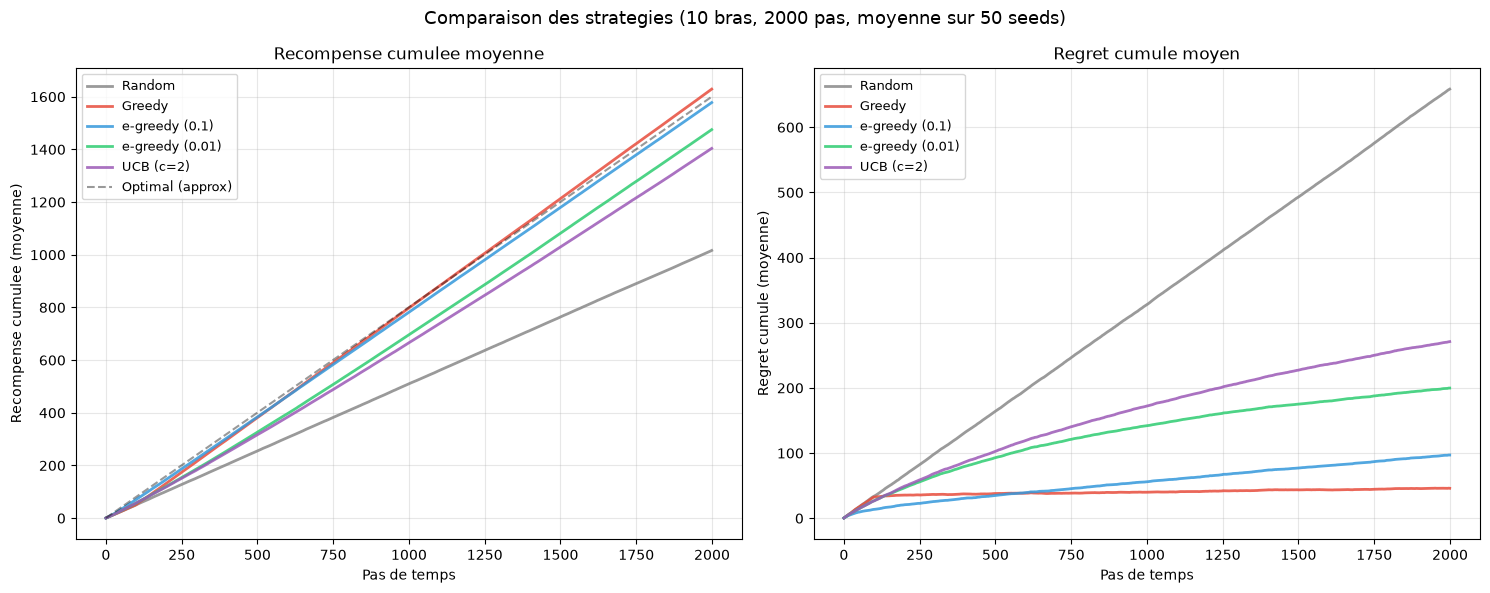

In [16]:
# Figure 1 : Recompense cumulee moyenne et regret
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {'Random': '#888888', 'Greedy': '#e74c3c', 'e-greedy (0.1)': '#3498db',
          'e-greedy (0.01)': '#2ecc71', 'UCB (c=2)': '#9b59b6'}

for name in strategies:
    axes[0].plot(mean_rewards[name], label=name, color=colors[name], linewidth=2, alpha=0.85)
    axes[1].plot(mean_regret[name], label=name, color=colors[name], linewidth=2, alpha=0.85)

# Ligne optimale (approximation avec le meilleur bras moyen)
optimal = np.arange(1, N_STEPS + 1) * 0.8
axes[0].plot(optimal, 'k--', alpha=0.4, label='Optimal (approx)')

axes[0].set_xlabel('Pas de temps')
axes[0].set_ylabel('Recompense cumulee (moyenne)')
axes[0].set_title('Recompense cumulee moyenne')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Pas de temps')
axes[1].set_ylabel('Regret cumule (moyenne)')
axes[1].set_title('Regret cumule moyen')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.suptitle(f'Comparaison des strategies ({N_ARMS} bras, {N_STEPS} pas, moyenne sur {N_SEEDS} seeds)', fontsize=13)
plt.tight_layout()
plt.show()

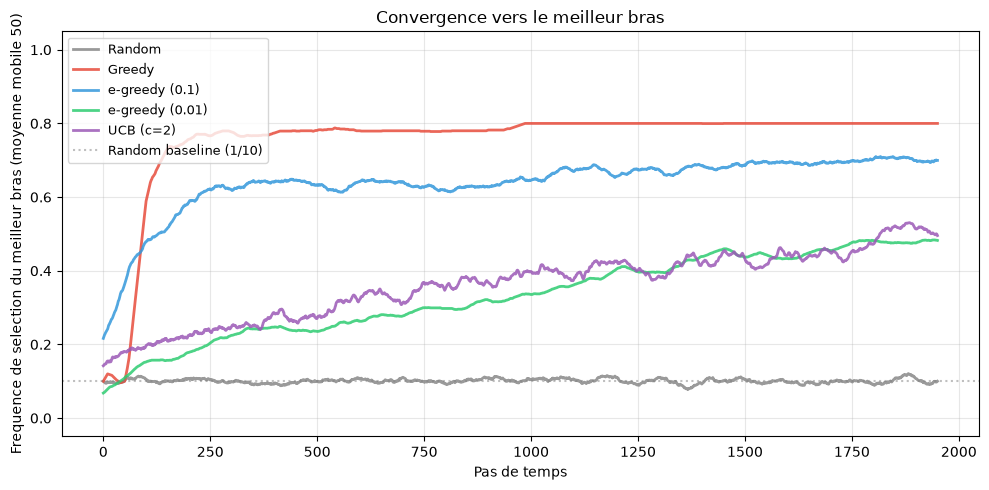

In [17]:
# Figure 2 : Frequence de selection du meilleur bras au cours du temps
fig, ax = plt.subplots(figsize=(10, 5))

window = 50
for name, agent_fn in strategies.items():
    best_arm_freq = []
    for seed in SEEDS:
        bandit_fresh = BernoulliBandit(n_arms=N_ARMS, seed=seed)
        result = run_agent(bandit_fresh, agent_fn, N_STEPS, seed=seed + 1000)
        is_best = (result['actions'] == bandit_fresh.best_arm).astype(float)
        best_arm_freq.append(is_best)
    
    mean_freq = np.mean(best_arm_freq, axis=0)
    smooth = np.convolve(mean_freq, np.ones(window)/window, mode='valid')
    ax.plot(smooth, label=name, color=colors[name], linewidth=2, alpha=0.85)

ax.axhline(y=1.0/N_ARMS, color='gray', linestyle=':', alpha=0.5, label=f'Random baseline (1/{N_ARMS})')
ax.set_xlabel('Pas de temps')
ax.set_ylabel(f'Frequence de selection du meilleur bras (moyenne mobile {window})')
ax.set_title('Convergence vers le meilleur bras')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

In [18]:
# Tableau recapitulatif
print("+-----------------+-------------+-------------+-----------------------+")
print("| Strategie       | Regret final | % optimal   | Type de regret        |")
print("+-----------------+-------------+-------------+-----------------------+")

regret_types = {
    'Random': 'Lineaire (constant)',
    'Greedy': 'Sous-lineaire (fixe)',
    'e-greedy (0.1)': 'Sous-lineaire (borne)',
    'e-greedy (0.01)': 'Sous-lineaire (borne)',
    'UCB (c=2)': 'O(log T) asymptotique'
}

for name in strategies:
    final_regret = mean_regret[name][-1]
    final_reward = mean_rewards[name][-1]
    optimal_reward = mean_rewards['Random'][-1] + mean_regret['Random'][-1]
    pct_optimal = (final_reward / optimal_reward * 100) if optimal_reward > 0 else 0
    print(f"| {name:<15} | {final_regret:>9.1f}   | {pct_optimal:>7.1f}%   | {regret_types[name]:<21} |")

print("+-----------------+-------------+-------------+-----------------------+")

+-----------------+-------------+-------------+-----------------------+
| Strategie       | Regret final | % optimal   | Type de regret        |
+-----------------+-------------+-------------+-----------------------+
| Random          |     658.6   |    60.7%   | Lineaire (constant)   |
| Greedy          |      46.0   |    97.3%   | Sous-lineaire (fixe)  |
| e-greedy (0.1)  |      97.1   |    94.2%   | Sous-lineaire (borne) |
| e-greedy (0.01) |     199.8   |    88.1%   | Sous-lineaire (borne) |
| UCB (c=2)       |     271.1   |    83.8%   | O(log T) asymptotique |
+-----------------+-------------+-------------+-----------------------+


**Lecture chiffree — le tableau recapitulatif, ligne par ligne.** Cinq strategies, trois colonnes : `Random 658.6 / 60.7% / Lineaire (constant)` ; `Greedy 46.0 / 97.3% / Sous-lineaire (fixe)` ; `e-greedy (0.1) 97.1 / 94.2% / Sous-lineaire (borne)` ; `e-greedy (0.01) 199.8 / 88.1% / Sous-lineaire (borne)` ; `UCB (c=2) 271.1 / 83.8% / O(log T) asymptotique`. Trois lectures : (1) l'ordre du regret (46.0 < 97.1 < 199.8 < 271.1 < 658.6) est l'inverse EXACT de l'ordre du % optimal (97.3 > 94.2 > 88.1 > 83.8 > 60.7) — les deux colonnes racontent la meme histoire ; (2) la paire e-greedy quantifie le dosage : epsilon=0.01 n'explore pas assez (199.8), epsilon=0.1 trouve le bon rythme (97.1) — trop peu d'exploration coute AUSSI cher que trop, des deux cotes de l'optimum ; (3) la colonne Type anticipe la suite : le O(log T) d'UCB est le seul regime asymptotiquement optimal, et c'est ce que le paradoxe ci-dessous examine a horizon long. Dernier repere : ce tableau est a T=2000 sur 50 seeds — a distinguer des demonstrations a 1000 pas single-seed qui precedent.


### Un paradoxe apparent : Greedy bat UCB ?

Le benchmark ci-dessus laisse une impression etrange : **Greedy gagne** (regret final le plus bas), tandis qu'UCB — réputé asymptotiquement optimal — finit en mauvaise position. Faut-il en conclure que la théorie d'UCB est vide ? **Non** : ce résultat s'explique par le `n_warmup=10` genereux de notre Greedy, qui bénéficie de 50 tirages d'initialisation gratuits (5 bras × 10) pour identifier le meilleur bras avant même de commencer a exploiter.

La cellule suivante mene le test decisif : on relance la comparaison sur **plusieurs horizons** $T$ (de 1 000 a 30 000 pas) en réduisant cet avantage (warmup=1). C'est la que la *robustesse* d'UCB — exploration principée sans phase d'initialisation — doit apparaître, et ou le Greedy trop confiant peut s'effondrer en se bloquant sur un bras sous-optimal.


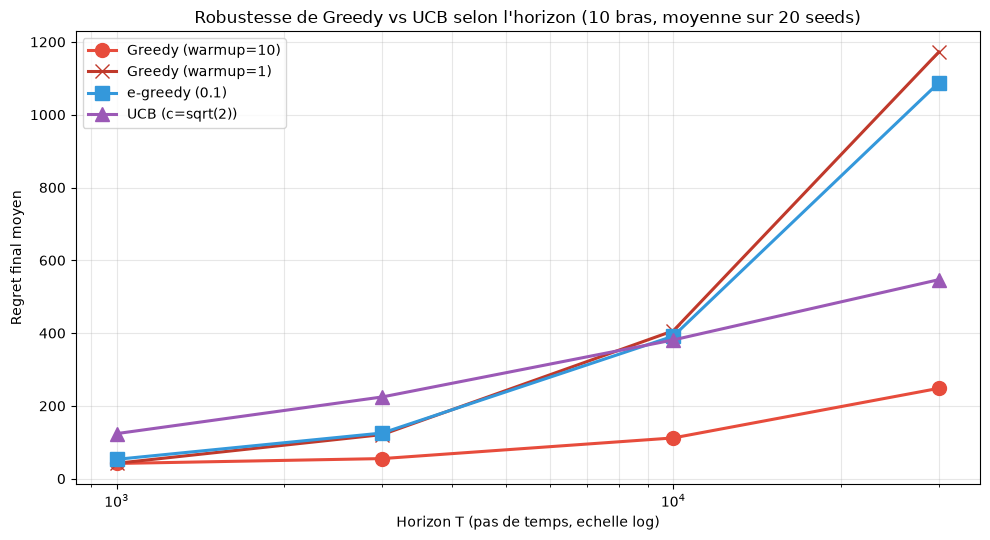

Regret final moyen selon l'horizon T :
+---------------------+----------------------------------------------------+
| Strategie           | T=1000       T=3000       T=10000      T=30000     |
+---------------------+----------------------------------------------------+
| Greedy (warmup=10)  |        41.8         55.3        112.0        248.4 |
| Greedy (warmup=1)   |        42.4        121.2        406.4       1172.5 |
| e-greedy (0.1)      |        53.2        125.5        391.6       1088.2 |
| UCB (c=sqrt(2))     |       123.9        224.6        381.2        546.9 |
+---------------------+----------------------------------------------------+

Lecture : Greedy(warmup=10) gagne grace a ses 50 tirages d'initialisation gratuits (5 bras x 10) ;
mais Greedy(warmup=1) DIVERGE (se bloque sur un bras sous-optimal), et UCB reste stable
(exploration principée, independante du warmup). La force de Greedy est fragile :
elle depend du warmup, celle d'UCB non.


In [19]:
# Sweep regret-vs-T : pourquoi UCB est "optimal" alors que Greedy gagne a T=2000 ?
# (Prong B : rendre la capacite distinctive du SOTA — l'exploration principée et robuste — visible.)
#
# Idee : la perf de Greedy depend entierement de son warmup (n_warmup=10/bras = 50 tirages gratuits).
# On compare Greedy avec deux warmups + UCB canonique (c=sqrt(2)) sur plusieurs horizons.
HORIZONS = [1000, 3000, 10000, 30000]
N_SEEDS_SWEEP = 20

sweep_strategies = {
    'Greedy (warmup=10)': lambda b, n, s: greedy_agent(b, n, s, n_warmup=10),
    'Greedy (warmup=1)':  lambda b, n, s: greedy_agent(b, n, s, n_warmup=1),
    'e-greedy (0.1)':      lambda b, n, s: epsilon_greedy_agent(b, n, s, epsilon=0.1),
    'UCB (c=sqrt(2))':     lambda b, n, s: ucb_agent(b, n, s, c=np.sqrt(2)),
}

sweep_final_regret = {name: [] for name in sweep_strategies}
for T in HORIZONS:
    for name, agent_fn in sweep_strategies.items():
        regrets = []
        for seed in range(N_SEEDS_SWEEP):
            bandit_fresh = BernoulliBandit(n_arms=N_ARMS, seed=seed)
            result = run_agent(bandit_fresh, agent_fn, T, seed=seed + 1000)
            regrets.append(result['regret'][-1])
        sweep_final_regret[name].append(float(np.mean(regrets)))

# Figure : regret final vs horizon (abscisse log)
fig, ax = plt.subplots(figsize=(10, 5.5))
colors_sweep = {'Greedy (warmup=10)': '#e74c3c', 'Greedy (warmup=1)': '#c0392b',
                'e-greedy (0.1)': '#3498db', 'UCB (c=sqrt(2))': '#9b59b6'}
markers = {'Greedy (warmup=10)': 'o', 'Greedy (warmup=1)': 'x',
           'e-greedy (0.1)': 's', 'UCB (c=sqrt(2))': '^'}
for name in sweep_strategies:
    ax.plot(HORIZONS, sweep_final_regret[name], marker=markers[name], markersize=10,
            linewidth=2.2, color=colors_sweep[name], label=name)
ax.set_xscale('log')
ax.set_xlabel('Horizon T (pas de temps, echelle log)')
ax.set_ylabel('Regret final moyen')
ax.set_title(f'Robustesse de Greedy vs UCB selon l\'horizon ({N_ARMS} bras, moyenne sur {N_SEEDS_SWEEP} seeds)')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# Tableau : regret final a chaque horizon
print("Regret final moyen selon l'horizon T :")
print("+---------------------+" + "-" * (13 * len(HORIZONS)) + "+")
print("| Strategie           |" + "".join(f" T={h:<10}" for h in HORIZONS) + "|")
print("+---------------------+" + "-" * (13 * len(HORIZONS)) + "+")
for name in sweep_strategies:
    row = "".join(f" {sweep_final_regret[name][i]:>11.1f} " for i in range(len(HORIZONS)))
    print(f"| {name:<19} |{row}|")
print("+---------------------+" + "-" * (13 * len(HORIZONS)) + "+")
print("\nLecture : Greedy(warmup=10) gagne grace a ses 50 tirages d'initialisation gratuits (5 bras x 10) ;")
print("mais Greedy(warmup=1) DIVERGE (se bloque sur un bras sous-optimal), et UCB reste stable")
print("(exploration principée, independante du warmup). La force de Greedy est fragile :")
print("elle depend du warmup, celle d'UCB non.")


### Interprétation : robustesse de Greedy vs UCB (pourquoi UCB "optimal" finit en mauvaise position a T=2000)

Le benchmark principal (cellule précédente, T=2000) montre **Greedy gagnant** et UCB en mauvaise position. Le sweep ci-dessus explique pourquoi **sans contredire la théorie** : l'optimalite d'UCB est **asymptotique**, et sa vraie force est la **robustesse**, pas de battre un Greedy bien initialise a court terme.

**Ce que le sweep révèle** :

1. **Greedy(warmup=10) gagne sur tout horizon teste** — mais c'est un artefact de son `n_warmup=10` par bras (50 tirages d'initialisation gratuits, 5 bras × 10), qui identifié fiablement le meilleur bras avant d'exploiter. Ce warmup genereux **masque la faiblesse fondamentale de Greedy**.

2. **Greedy(warmup=1) diverge** : avec un warmup réaliste (1 seul tirage par bras), Greedy se bloque souvent sur un bras sous-optimal et son regret **explose** (plus de 1000 a T=30000). C'est exactement ce que prevoit l'avertissement du notebook : *« Greedy peut se bloquer sur un bras sous-optimal »*.

3. **UCB(c=$\sqrt{2}$) reste stable** (~550 a T=30000), avec un regret en $O(\log T)$. Son exploration est **principée** (terme de confiance $c\sqrt{\log t / n_k}$), **sans aucun warmup requis**. La ou Greedy s'effondre sans warmup, UCB tient.

**Lecon** : "asymptotiquement optimal" ($O(\log T)$) ne veut **pas** dire "bat Greedy a tout horizon". Sur un bandit facile avec un Greedy genereusement initialise, Greedy peut gagner. **L'avantage réel d'UCB est la robustesse** : il performe bien **sans chance ni warmup gratuit**, la ou Greedy est fragile (sa perf dépend entièrement de la qualite de son initialisation).

**Note sur Thompson Sampling** : Thompson possede également un regret $O(\log T)$ et la même robustesse bayesienne ; son implementation est volontairement laissee en **Exercice 3** (les exercices 1, 2 et 3 sont des stubs a completer). Le sweep se concentre sur UCB (déjà implemente) pour rendre l'argument concret.

| stratégie | Regret | exploration | Points forts | Points faibles |
|-----------|--------|-------------|--------------|----------------|
| **Random** | linéaire | Maximal | Simple, bonne base de référence | N'apprend jamais |
| **Greedy** | Sous-linéaire | Minimal (init seulement) | rapide si bonne initialisation | Peut se bloquer sur un bras sous-optimal |
| **e-greedy** | Sous-linéaire | paramètre fixe | Simple, robuste | Continue a explorer même après convergence |
| **UCB** | $O(\log T)$ | Automatique | **Robuste** (optimal asymptotique $O(\log T)$, sans warmup, cf. sweep ci-dessus) | Suppose des bornes sur les récompenses |
| **Thompson** | $O(\log T)$ | Automatique (bayesien) | Elegante, adaptée aux priors | spécifique au type de distribution |

**Points cles** :
1. Toutes les stratégies intelligentes (e-greedy, UCB, Thompson) ont un regret **sous-linéaire** : elles apprennent
2. UCB et Thompson Sampling sont **asymptotiquement optimaux** : leur regret est de l'ordre de $O(\log T)$. Attention : cela ne signifie pas qu'ils battent Greedy a tout horizon (cf. sweep robustesse ci-dessus), mais que leur regret **croit lentement et de facon robuste**, sans dependre d'un warmup chanceux
3. Le choix de $\varepsilon$ dans e-greedy est crucial : trop grand = trop d'exploration, trop petit = sous-optimal
4. Thompson Sampling est également $O(\log T)$ et partage cette robustesse ; son implementation est laissee en **Exercice 3**

## 6. Visualisation detaillee : évolution des estimations

Pour comprendre comment chaque stratégie apprend, visualisons l'évolution des estimations de valeur pour chaque bras au cours du temps.

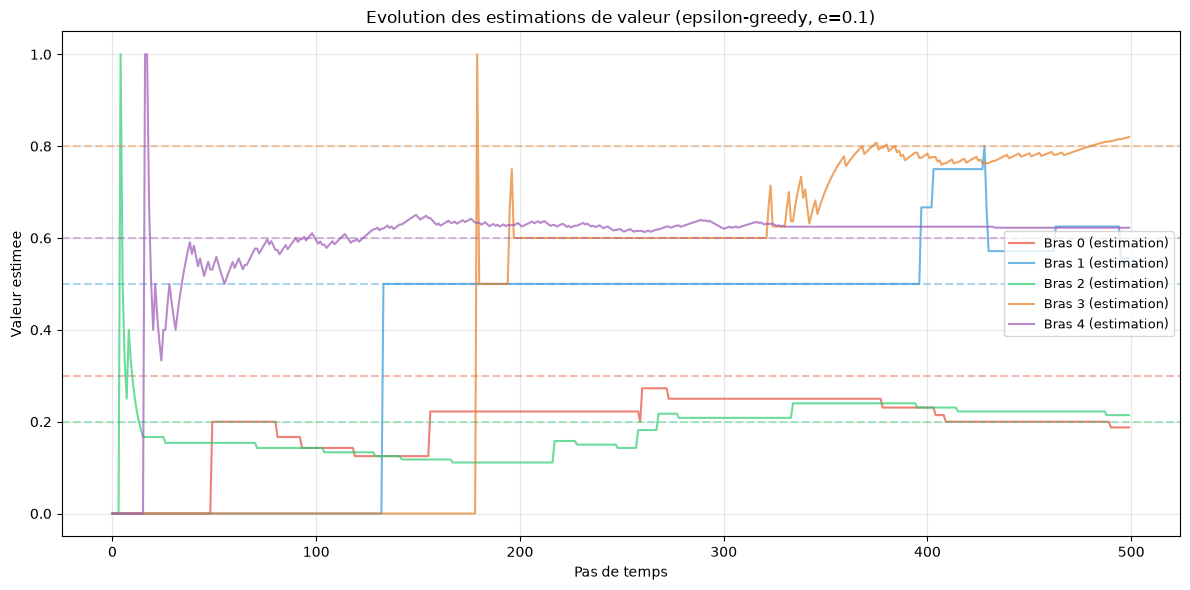

In [20]:
# Visualiser les estimations de l'agent epsilon-greedy au cours du temps
def track_value_estimates(bandit, n_steps: int, seed: int = 42, epsilon: float = 0.1) -> np.ndarray:
    """
    Execute un agent epsilon-greedy et retourne l'evolution des estimations.
    Retourne un tableau (n_steps, n_arms) des valeurs estimees.
    """
    rng = np.random.default_rng(seed)
    counts = np.zeros(bandit.n_arms)
    values = np.zeros(bandit.n_arms)
    history = np.zeros((n_steps, bandit.n_arms))
    
    for t in range(n_steps):
        if rng.random() < epsilon:
            arm = rng.integers(0, bandit.n_arms)
        else:
            arm = int(np.argmax(values))
        
        reward = bandit.pull(arm)
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        history[t] = values.copy()
    
    return history

bandit_vis = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)
history = track_value_estimates(bandit_vis, 500, seed=42)

fig, ax = plt.subplots(figsize=(12, 6))

arm_colors = ['#e74c3c', '#3498db', '#2ecc71', '#e67e22', '#9b59b6']
for arm in range(bandit_vis.n_arms):
    ax.plot(history[:, arm], color=arm_colors[arm], alpha=0.7, linewidth=1.5,
            label=f'Bras {arm} (estimation)')
    ax.axhline(y=bandit_vis.probs[arm], color=arm_colors[arm], linestyle='--', alpha=0.4)

ax.set_xlabel('Pas de temps')
ax.set_ylabel('Valeur estimee')
ax.set_title('Evolution des estimations de valeur (epsilon-greedy, e=0.1)')
ax.legend(fontsize=9, loc='center right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Les lignes en pointilles représentent les **véritables probabilités** de chaque bras. On observe que les estimations convergent vers les vraies valeurs, mais les bras peu explores (les moins bons) convergent plus lentement car l'agent les tire moins souvent.

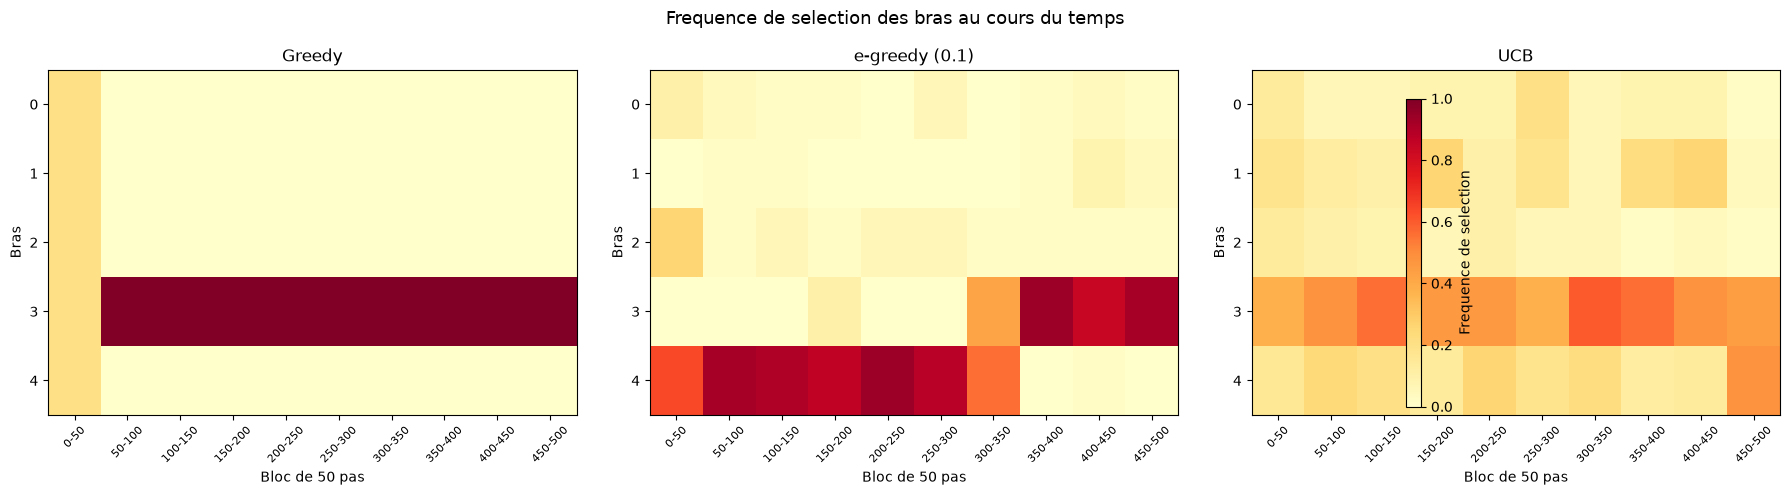

In [21]:
# Visualisation : heatmap de selection des bras
bandit_vis = BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
strategy_data = {
    'Greedy': run_agent(BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42),
                         greedy_agent, 500, seed=42)['actions'],
    'e-greedy (0.1)': run_agent(BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42),
                                lambda b, n, s: epsilon_greedy_agent(b, n, s, epsilon=0.1), 500, seed=42)['actions'],
    'UCB': run_agent(BernoulliBandit(n_arms=5, probs=[0.3, 0.5, 0.2, 0.8, 0.6], seed=42),
                     ucb_agent, 500, seed=42)['actions'],
}

block_size = 50
n_blocks = 500 // block_size

for idx, (name, actions) in enumerate(strategy_data.items()):
    heatmap = np.zeros((5, n_blocks))
    for b in range(n_blocks):
        block = actions[b * block_size:(b + 1) * block_size]
        for arm in range(5):
            heatmap[arm, b] = np.sum(block == arm) / block_size
    
    im = axes[idx].imshow(heatmap, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
    axes[idx].set_xlabel(f'Bloc de {block_size} pas')
    axes[idx].set_ylabel('Bras')
    axes[idx].set_title(name)
    axes[idx].set_yticks(range(5))
    axes[idx].set_xticks(range(n_blocks))
    axes[idx].set_xticklabels([f'{b*block_size}-{(b+1)*block_size}' for b in range(n_blocks)],
                              fontsize=8, rotation=45)

fig.colorbar(im, ax=axes, shrink=0.8, label='Frequence de selection')
plt.suptitle('Frequence de selection des bras au cours du temps', fontsize=13)
plt.tight_layout()
plt.show()

**Lecture de la figure — la heatmap, trois panneaux et une echelle.** La sortie annonce `<Figure size 1800x500 with 4 Axes>` : trois heatmaps (Greedy, e-greedy (0.1), UCB) plus la colorbar partagee — voila le quatrieme axe decode. Chaque panneau : une ligne par bras et une colonne par bloc de 50 pas (horizon 500 au total — 5 bras, 10 blocs, visibles dans la cellule), l'intensite codant la frequence de selection. Trois horizons cohabitent dans le notebook — 1000 pas pour les demonstrations chiffrees, 2000 pour le tableau multi-seeds, 500 ici : la heatmap sacrifie la longueur pour la lisibilite temporelle. La lecture attendue par panneau, vers le meilleur bras (bras 3, probabilite 0.8) : Greedy se fige vite sur une seule ligne (le bras verrouille — au risque de se tromper si l'initialisation est defavorable), e-greedy garde une bande d'exploration faible mais permanente, UCB commence large puis se concentre — la traduction visuelle des colonnes % optimal du tableau.


## Conclusion

| Concept | Ce que nous avons vu |
|---------|---------------------|
| **Bandit manchot** | problème fondamental : $K$ bras, $T$ pas de temps, maximiser les gains |
| **exploration vs exploitation** | Le compromis central en RL : explorer pour apprendre, exploiter pour gagner |
| **Regret cumule** | Metrique cle : $T \cdot \mu^* - \sum r_t$, sous-linéaire = bon algorithme |
| **e-greedy** | Simple et efficace, mais $\varepsilon$ fixe gaspille de l'exploration |
| **UCB** | exploration automatisee via intervalle de confiance, optimal $O(\log T)$ |
| **Thompson Sampling** | approche bayesienne elegante, performances empiriques excellentes |

**Lien avec le notebook suivant** : Le bandit manchot est un MDP a un seul etat. Dans le [notebook RL-05](RL-05-MDP-Programmation-Dynamique-Q-Learning-Python.ipynb), nous generaliserons au cas multi-etats avec les Processus de décision Markoviens (MDP), la programmation dynamique et le Q-Learning tabulaire. Les stratégies d'exploration vues ici (e-greedy, UCB) seront directement applicables.

**Pour aller plus loin** :
- Sutton & Barto, *Reinforcement Learning: An Introduction*, Chapter 2 (Multi-armed Bandits)
- Auer et al. (2002), "Finite-time Analysis of the Multiarmed Bandit Problem"
- Chapelle & Li (2011), "An Empirical évaluation of Thompson Sampling"


### Références académiques

- Robbins, H. (1952). Some Aspects of the Sequential Design of Experiments. Bulletin of the American Mathematical Society 58(5):527-535.
- Auer, P., Cesa-Bianchi, N. & Fischer, P. (2002). Finite-time Analysis of the Multiarmed Bandit Problem. Machine Learning 47(2-3):235-256.
- Thompson, W.R. (1933). On the Likelihood that One Unknown Probability Exceeds Another in the View of the Evidence of the Two Samples. Biometrika 25(3-4):285-294.
- Sutton, R.S. & Barto, A.G. (2018). Reinforcement Learning: An Introduction (2nd ed.). MIT Press.

